<p style="text-align: right; margin: 0; line-height: 0;"><img width="100px" height="auto" src="../../.admin/img/eth_logo.png"></p>

<h1 style="text-align: center;">01 Data and Signals</h1>
<hr>


## **8. The Shannon-Nyquist Sampling Theorem**


<div class="alert alert-light">

  **Name:** Stefan Sykes
  
  **Matriculation Number:** 11-250-693

</div>

<style>
.reveal .jp-CodeCell .jp-Cell-inputWrapper,
.reveal .jp-CodeCell .jp-InputArea,
.reveal div.code_cell div.input,
.reveal div.code_cell .input_area {
    display: none !important;
}
</style>


### 8.1 Introduction

Notebook [**Converting Analog Signals to Digital Time Series**](01.4_Converting_Analog_Signals_to_Digital_Time_Series.ipynb) stated a condition for sampling without loss: if a signal has no frequency content above $f_{\max}$, then a sampling rate $f_s>2f_{\max}$ allows the original signal to be reconstructed exactly. That notebook asserted the condition and showed what goes wrong when it is violated. It did not show where the factor of two comes from, or why the inequality has to be strict.

This notebook derives the result step by step, and then checks every step against numbers computed from the signal itself.

The argument has a shape worth holding in mind before the algebra starts. Sampling is not an approximation of a signal. It is a **multiplication** of the signal by a train of regularly spaced spikes. Multiplication in the time domain does something specific and entirely predictable in the frequency domain, and once we know what it does, the condition $f_s>2f_{\max}$ follows from a single picture in three lines of algebra.

The five steps are:

1. Describe the signal $x(t)$ and state what band-limited means (Section 8.2).
2. Write the sampling function $s(t)$ as a Fourier series (Section 8.3).
3. Multiply the two, and see what the product does to the spectrum (Section 8.4).
4. Ask when the result can be untangled again, which gives the theorem (Section 8.5).
5. Recover the original signal from its samples (Section 8.6).

Each figure reports the numbers it measures, so the claims can be checked against the signal itself rather than taken on trust.

**A note on reading this notebook.** Every step is presented twice, once as a figure and once as algebra. The figures carry the argument on their own. If mathematical notation is not your working language, follow the pictures and the sentences around them, and treat the equations as a precise restatement of what the picture has already shown.


In [1]:
from pathlib import Path
from runpy import run_path

_helper = next(root / ".admin/notebooks/sampling_theorem.py"
               for root in (Path.cwd(), *Path.cwd().parents)
               if (root / ".admin/notebooks/sampling_theorem.py").is_file())
_sampling = run_path(str(_helper))


### 8.2 Step 1: The Signal $x(t)$

We use the same example signal as notebook 01.4, so that the two notebooks describe the same case:

$$
x(t)=0.5\sin(2\pi\,6t)+0.5\sin(2\pi\,20t).
$$

It contains exactly two frequencies, 6 Hz and 20 Hz. The higher of the two is

$$
f_{\max}=20\ \mathrm{Hz}.
$$

A signal is **band-limited** when its spectrum is zero beyond some finite frequency:

$$
X(f)=0 \qquad\text{for}\qquad |f|>f_{\max}.
$$

This is the one assumption the theorem needs. Everything that follows depends on it, and nothing that follows works without it.

The figure below shows the signal in both domains. The spectrum is drawn **two-sided**, with negative as well as positive frequencies. Notebook 01.4 used a one-sided spectrum, which is the more convenient display for reading off component amplitudes. Here the two-sided view is necessary: the collision that the theorem forbids happens between the positive-frequency part of one copy of the spectrum and the negative-frequency part of its neighbour, and a one-sided plot hides exactly that.


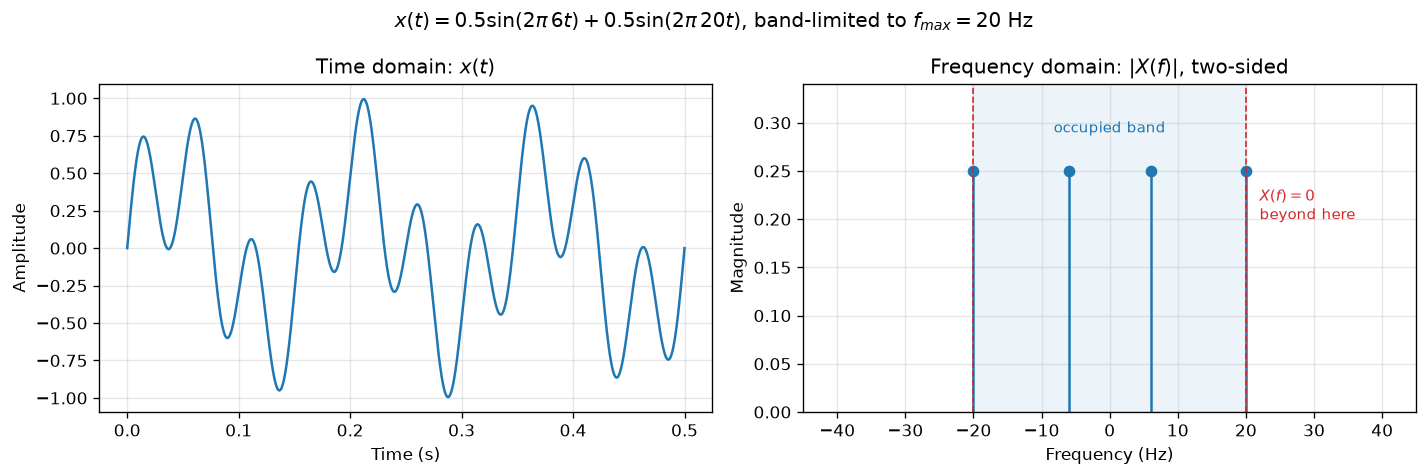

In [2]:
_sampling["show_signal_and_spectrum"]()


No physical signal is perfectly band-limited, so in practice an **anti-aliasing filter** is placed ahead of the converter to attenuate content above the band of interest, as described in Section 4.3.3 of notebook 01.4. The theorem is proved for the idealized case in which the filtering has already been done, and Section 8.8 returns to what the filter costs in a real system.


### 8.3 Step 2: The Sampling Function $s(t)$

#### 8.3.1 Ideal Sampling as a Multiplication

Measuring a signal at regular instants $t=nT_s$ can be written as multiplying it by a function that is zero everywhere except at those instants. That function is a train of spikes:

$$
s(t)=\sum_{n=-\infty}^{\infty}\delta(t-nT_s).
$$

Here $\delta$ is the **Dirac delta**, an idealized spike of zero width and unit area. We need only one of its properties, the **sifting property**: multiplying any continuous function by a delta positioned at $t=a$ and integrating returns the single value of that function at $a$,

$$
\int_{-\infty}^{\infty} x(t)\,\delta(t-a)\,dt = x(a).
$$

That is precisely what a measurement does, which is why $s(t)$ is the right model for a sampler. Treating $\delta$ as though it were an ordinary function is a convenient shorthand rather than a rigorous definition. The formal treatment belongs to the theory of distributions and is not needed for the argument here.


#### 8.3.2 The Fourier Series of the Sampling Function

The train $s(t)$ repeats itself exactly every $T_s$ seconds. Any periodic function can be written as a sum of harmonics of its repetition rate $f_s=1/T_s$, so $s(t)$ has a Fourier series

$$
s(t)=\sum_{k=-\infty}^{\infty}c_k\,e^{j2\pi kf_st},
$$

whose coefficients are given by a single integral over one period:

$$
c_k=\frac{1}{T_s}\int_{-T_s/2}^{T_s/2}s(t)\,e^{-j2\pi kf_st}\,dt.
$$

Within the window from $-T_s/2$ to $T_s/2$ the train contains exactly one spike, the one at $t=0$. The integral is therefore just the sifting property applied to $e^{-j2\pi kf_st}$ at $t=0$:

$$
c_k=\frac{1}{T_s}\int_{-T_s/2}^{T_s/2}\delta(t)\,e^{-j2\pi kf_st}\,dt=\frac{1}{T_s}\,e^{0}=\frac{1}{T_s}.
$$

The index $k$ has disappeared. **Every coefficient is the same number $1/T_s$**, which gives

$$
s(t)=\frac{1}{T_s}\sum_{k=-\infty}^{\infty}e^{j2\pi kf_st}.
$$

This is the hinge of the entire proof, and it is worth stating in words: the sampling function contains every multiple of the sampling rate, without end, and each one carries exactly the same weight. Nothing about a train of spikes is concentrated at low frequencies.

Use the slider to add harmonic pairs one at a time. The partial sum is real-valued and can be written with cosines,

$$
s_K(t)=\frac{1}{T_s}\left[1+2\sum_{k=1}^{K}\cos(2\pi kf_st)\right],
$$

because the terms at $+k$ and $-k$ combine. At $K=0$ the sampling function is nothing but its average value $1/T_s$, a flat line. Each harmonic added after that raises the curve at the sampling instants and adds finer oscillations between them. These ripples are Fourier-truncation ringing, analogous to the Gibbs behaviour seen in notebook [**Fourier Approximation of a Rectangular Pulse**](01.3_Fourier_Approximation_of_a_Rectangular_Pulse.ipynb). The ideal spike train is reached only in the limiting, distributional sense; no finite number of harmonics reproduces it exactly.

The lower panel shows the coefficients themselves. They sit at $0,\pm f_s,\pm 2f_s,\dots$, all at the same height $1/T_s$, and they continue past the edge of the plot without ever decaying.


In [3]:
_sampling["show_impulse_train_series"]()


### 8.4 Step 3: Sampling Multiplies, and Multiplication Shifts

#### 8.4.1 The Sampled Signal in Time

Ideal sampling is the product of the signal and the sampling function:

$$
x_s(t)=x(t)\,s(t)=\sum_{n=-\infty}^{\infty}x(t)\,\delta(t-nT_s)=\sum_{n=-\infty}^{\infty}x(nT_s)\,\delta(t-nT_s).
$$

The final step is the sifting property once more: a delta positioned at $nT_s$ only ever sees the value $x(nT_s)$. The result is a train of spikes whose heights are the sample values, and those numbers $x(nT_s)$ are exactly the sequence $x[n]$ from notebook 01.4.


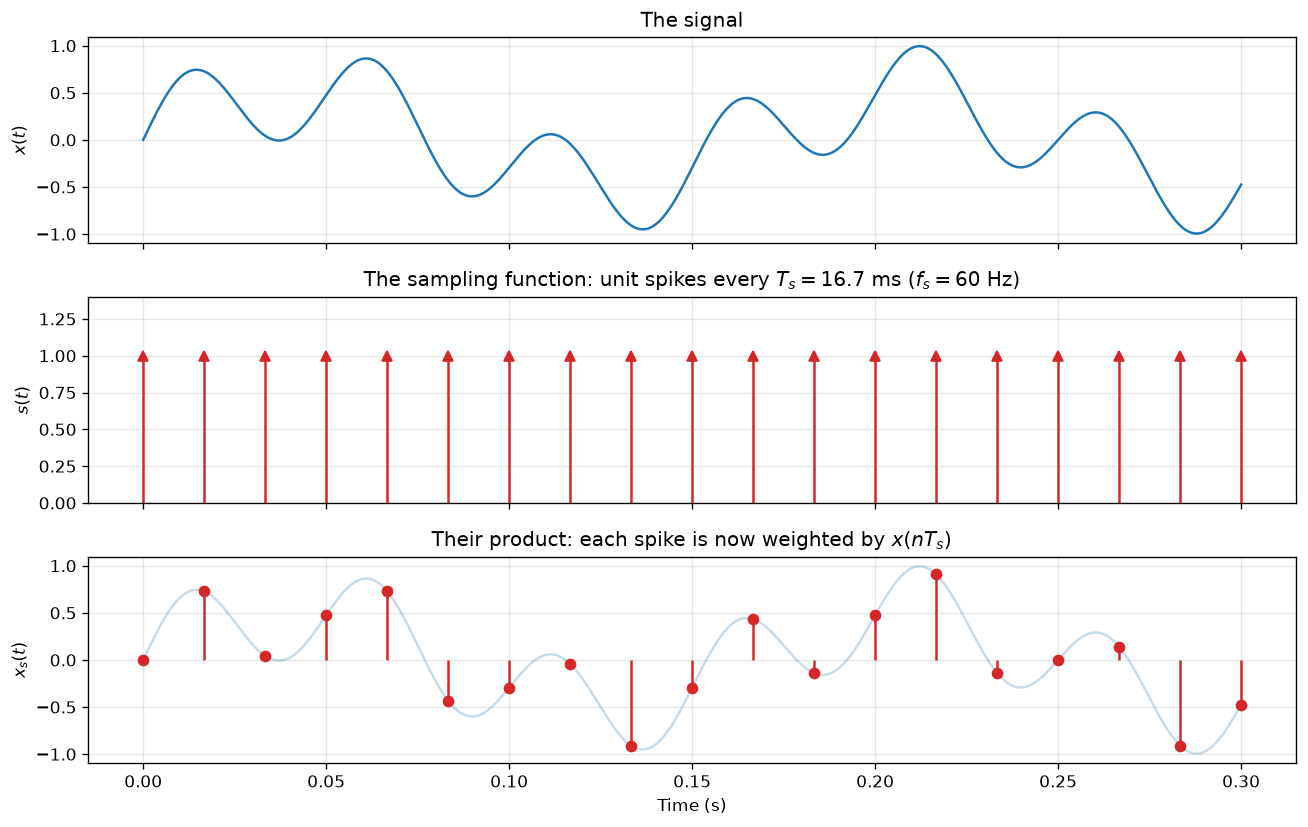

In [4]:
_sampling["show_multiplication"]()


#### 8.4.2 The Same Product Seen in Frequency

Now substitute the Fourier series from Section 8.3.2 into the product, in place of the spike form:

$$
x_s(t)=x(t)\cdot\frac{1}{T_s}\sum_{k=-\infty}^{\infty}e^{j2\pi kf_st}
      =\frac{1}{T_s}\sum_{k=-\infty}^{\infty}x(t)\,e^{j2\pi kf_st}.
$$

Read the right-hand side one term at a time. Each term is the original signal multiplied by a complex exponential at frequency $kf_s$. Multiplying by $e^{j2\pi f_0t}$ has one simple effect in the frequency domain: it slides the entire spectrum up by $f_0$ and leaves its shape untouched. Writing $\mathcal{F}$ for the Fourier transform,

$$
\mathcal{F}\!\left\{x(t)\,e^{j2\pi kf_st}\right\}=X(f-kf_s).
$$

This is the **modulation** property, the same relationship notebook 01.3 used when it showed that delaying a waveform multiplies its transform by a phase factor, with the roles of the two domains exchanged.

The Fourier transform adds term by term, so the transform of the whole sum is the sum of the shifted transforms:

$$
X_s(f)=\frac{1}{T_s}\sum_{k=-\infty}^{\infty}X(f-kf_s).
$$

**Sampling a signal produces an unlimited number of copies of its spectrum, one centred at every multiple of the sampling rate.** Note what has not happened: nothing is lost at this point, and nothing is distorted. Every copy is a faithful and complete reproduction of $X(f)$, scaled by $1/T_s$.

Before watching that happen, it is worth being explicit about what is being copied. The proof never uses the particular shape of $X(f)$. It uses one fact only, that $X(f)$ is zero outside $\pm f_{\max}$, so the figures let you choose among three spectra that all satisfy it.


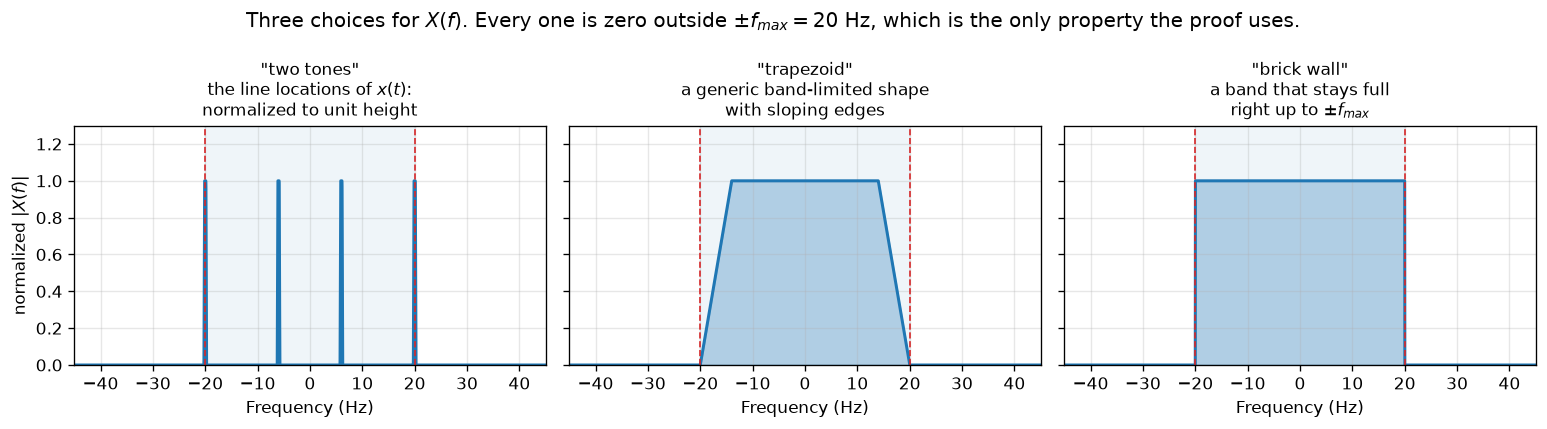

In [5]:
_sampling["show_spectrum_choices"]()


The first, **two tones**, uses the frequency locations of the genuine spectrum from Section 8.2: one line for each of the 6 Hz and 20 Hz components, on both sides of zero. The display normalizes the lines to unit height; their actual two-sided magnitude in Section 8.2 is 0.25. The other two are normalized stand-ins. They occupy the same band but fill it continuously, which makes it far easier to see when copies run into one another, and most real signals, such as speech or a sensor trace, look more like these than like a pair of lines.

Now add copies one at a time, and switch $X(f)$ between the three options. Whatever you choose, the same thing happens: the chosen spectrum reappears unchanged around every multiple of $f_s$, scaled by the same factor $1/T_s$. Because the displayed spectra are normalized to unit peak, their displayed copies reach $1/T_s$.


In [6]:
_sampling["show_spectral_replicas"]()


### 8.5 Step 4: When Can the Copies Be Separated Again?

Sampling produced copies. Recovering $x(t)$ means keeping one copy and discarding all the others, which is possible if and only if the copies do not run into one another.

Take two neighbouring copies, the one centred at $0$ and the one centred at $f_s$:

- the copy at $k=0$ occupies $[-f_{\max},\,f_{\max}]$,
- the copy at $k=1$ occupies $[f_s-f_{\max},\,f_s+f_{\max}]$.

They stay clear of each other exactly when the lower edge of the upper copy lies above the upper edge of the lower one:

$$
f_s-f_{\max}>f_{\max}.
$$

Adding $f_{\max}$ to both sides gives

$$
f_s>2f_{\max}.
$$

That is the **Shannon-Nyquist sampling theorem**. The factor of two is neither a safety margin nor a rule of thumb. It is the width of the signal's band counted twice, once for the positive frequencies and once for the negative ones, because each copy has to clear both halves of its neighbour.

Two pieces of vocabulary follow. The rate $2f_{\max}$ is the **Nyquist rate**, the boundary set by the signal's band limit. Rates strictly above it satisfy the safe general condition used here; exact equality needs the separate treatment in Section 8.7. Half of a chosen sampling rate, $f_s/2$, is the **Nyquist frequency**, the boundary of its baseband representation.

Move the slider and watch the copies slide past one another, and use the $X(f)$ control to change the spectrum being copied.

The upper panel marks in red any content that comes from a copy other than the original and lands inside the passband $|f|<f_s/2$. That is what makes recovery impossible, because the filter cannot tell such content apart from the signal itself. The displayed spectra are normalized to unit height before sampling; multiplication by the sampling function scales every replica by $1/T_s=f_s$. The vertical axis is held fixed across the slider range so that this scaling is visible.

The lower panel zooms into the passband and compares what the filter hands back with the spectrum we wanted. The filter's own gain of $T_s$ cancels the $1/T_s$ that sampling introduced, so this comparison is in the units of the original $X(f)$. Below 40 Hz the two curves separate near the band edges, and the red area between them is the error sampling has introduced. Above 40 Hz they are identical and the red area vanishes.


In [7]:
_sampling["show_overlap_condition"]()


**The case at exactly $f_s=2f_{\max}$ deserves attention**, and the figure marks it in orange rather than red or green. At that rate the two copies do not overlap across an interval; they meet at the single frequency $\pm f_{\max}$. For a spectrum that is a smooth shape, one shared point carries no energy, so the picture looks harmless and the measured error is zero. For a signal that has an actual spectral line at $f_{\max}$, such as a pure sinusoid, that shared point is where the whole of the component's energy sits, and the two copies collide head on. Section 8.7 works through this case. It is the reason the theorem is stated with a strict inequality.

**Both behaviours are visible in the figure.** Set $f_s=40$ Hz with $X(f)$ on *trapezoid* or *brick wall*: there is no red, and the measured error is zero. Now hold $f_s$ at 40 Hz and switch to *two tones*: the red returns, because the 20 Hz line belonging to the copy at $k=1$ lands exactly on top of the original's own line at 20 Hz. The smooth stand-in shapes hide this failure. The true spectrum of our test signal does not.

When copies do overlap, frequencies belonging to a neighbouring copy land inside the passband, where they are indistinguishable from genuine low-frequency content. That is **aliasing**, introduced in Section 4.3.3 of notebook 01.4, and the overlap picture is the reason it happens. A 20 Hz component sampled at 30 Hz has its $k=-1$ copy centred at $-30$ Hz, which places an image of that component at $|20-30|=10$ Hz: inside the passband, and beyond any later repair.


### 8.6 Step 5: Recovering the Signal from Its Samples

Suppose the condition holds. The copy at $k=0$ then sits alone within $|f|<f_s/2$, and an **ideal lowpass filter** that keeps that interval and rejects everything else returns the original spectrum exactly:

$$
H(f)=T_s\operatorname{rect}\!\left(\frac{f}{f_s}\right),
\qquad
X_s(f)\,H(f)=X(f).
$$

The factor $T_s$ cancels the $1/T_s$ that sampling introduced.

A filter that is rectangular in frequency is a sinc in time. Notebook 01.3 established this pair in the other direction, a rectangular pulse in time transforming into a sinc in frequency; the Fourier transform is symmetric enough that the same relationship holds with the two domains exchanged. The impulse response of $H(f)$ is therefore

$$
h(t)=\operatorname{sinc}\!\left(\frac{t}{T_s}\right),
\qquad
\operatorname{sinc}(u)=\frac{\sin(\pi u)}{\pi u}.
$$

Filtering in frequency is convolution in time, and convolving a train of weighted spikes with $h(t)$ places one copy of $h$ at each spike, scaled by that spike's height. The result is the **interpolation formula**:

$$
x(t)=\sum_{n=-\infty}^{\infty}x[n]\operatorname{sinc}\!\left(\frac{t-nT_s}{T_s}\right).
$$

The signal between the samples was never stored, and it never needed to be. Under the band-limiting assumption, the samples already determine it.

The sinc is built for this job. It equals 1 at $t=0$ and exactly 0 at every other multiple of $T_s$, so each term contributes its own sample value at its own instant and contributes nothing at any other sample instant. The sum therefore passes exactly through every sample, whatever the sampling rate happens to be. Whether it also follows the original signal **between** the samples is precisely what the theorem decides.

Move the slider below 40 Hz and watch what happens. The blue reconstruction still touches every red sample, but between them it traces a different and slower waveform than the dashed original. The samples are not wrong. There are simply not enough of them to determine which signal produced them.

Two idealizations should be named. The sum runs over all $n$ from $-\infty$ to $\infty$, and the ideal filter responds before its input arrives, so neither is physically realizable and real converters approximate both. The figures sample a wider interval of time than they display to reduce truncation effects. Any small nonzero error reported above the Nyquist rate is residual error from this finite numerical approximation, not aliasing.


In [8]:
_sampling["show_sinc_reconstruction"]()


### 8.7 Why the Inequality Is Strict

The condition is $f_s>2f_{\max}$, not $f_s\ge2f_{\max}$. The boundary case fails, and it is worth seeing exactly how.

Take a single sinusoid at exactly $f_{\max}$ with an arbitrary phase, $x(t)=\sin(2\pi f_{\max}t+\phi)$, and sample it at exactly $f_s=2f_{\max}$. The sampling instants are $t=n/(2f_{\max})$, so the samples are

$$
x[n]=\sin(\pi n+\phi)=\sin(\pi n)\cos\phi+\cos(\pi n)\sin\phi=(-1)^n\sin\phi,
$$

because $\sin(\pi n)=0$ for every integer $n$. The term carrying $\cos\phi$ has dropped out entirely. Whatever the phase, the samples merely alternate between $+\sin\phi$ and $-\sin\phi$, and the reconstruction has amplitude $|\sin\phi|$ instead of 1.

At $\phi=90^\circ$ the samples land on the peaks and the amplitude is correct. At $\phi=0$ every sample lands on a zero crossing, the sample sequence is all zeros, and the reconstruction is the zero signal: the component disappears without leaving a trace. Every phase in between loses some part of the amplitude.

A sampling rate whose result depends on the phase of the incoming signal is not a usable rate, and the strict inequality is what excludes it. The figure below reports the recovered amplitude alongside the predicted $|\sin\phi|$ at each phase, so the prediction can be checked directly.


In [9]:
_sampling["show_critical_phase"]()


### 8.8 Key Takeaways

Sampling is a multiplication of the signal by a train of spikes, and that train has a Fourier series in which every multiple of the sampling rate appears carrying the identical weight $1/T_s$. Multiplying by each of those harmonics shifts the signal's spectrum by that harmonic's frequency, so sampling replaces the single spectrum $X(f)$ with an unending row of copies spaced $f_s$ apart. Everything the theorem says follows from that one picture.

Recovering the signal means isolating one copy. Copies of width $2f_{\max}$ spaced $f_s$ apart stay clear of one another exactly when $f_s>2f_{\max}$, and the factor of two is the width of the band counted on both sides of zero. When the condition holds, an ideal lowpass filter returns $X(f)$ exactly, and in the time domain that filter is the sinc interpolation formula, which rebuilds $x(t)$ from the samples alone. When the condition fails, a neighbouring copy folds into the passband, and the intruding frequencies cannot be told apart from genuine ones. No amount of later processing separates them, because the information that would distinguish them was never recorded in the first place.

For a technology decision, three consequences carry over.

**The sampling rate is set by the signal, not by the budget.** It follows from the highest frequency that has to survive. Choosing a rate is therefore a decision about which content to keep, and it is taken before any data is captured.

**Margin above the Nyquist rate is bought, not free.** Audio is sampled at 44.1 kHz rather than at exactly 40 kHz for a signal band-limited to 20 kHz. The additional 4.1 kHz exists because the anti-aliasing filter ahead of the converter cannot fall from passing to rejecting at a single frequency. It needs a transition band, and that band has to fit below $f_s/2$. The same margin also eases reconstruction: real digital interpolation and analog output filters have finite order and cannot reproduce the ideal sinc or brick-wall response exactly, especially near the cutoff. Margin costs data, at the raw rate $R=f_sB$ from notebook 01.4, so the choice is a direct trade between filter cost, data volume, and fidelity.

**Resolution cannot substitute for rate.** More bits per sample make each recorded value more precise. They do nothing whatsoever about aliasing, because aliasing is a question of which waveform produced the samples, not of how precisely each sample was written down. A 24-bit converter running too slowly records the wrong signal very accurately.


### 8.9 Literature / Background

1. Nyquist, H. (1928). [**Certain Topics in Telegraph Transmission Theory**](https://doi.org/10.1109/T-AIEE.1928.5055024). *Transactions of the American Institute of Electrical Engineers*, 47(2), 617-644.
2. Shannon, C. E. (1949). [**Communication in the Presence of Noise**](https://doi.org/10.1109/JRPROC.1949.232969). *Proceedings of the IRE*, 37(1), 10-21.
3. Unser, M. (2000). [**Sampling: 50 Years After Shannon**](https://doi.org/10.1109/5.843002). *Proceedings of the IEEE*, 88(4), 569-587.
4. Smith, S. W. (1997). [**The Scientist and Engineer's Guide to Digital Signal Processing, Chapter 3: ADC and DAC**](https://www.dspguide.com/ch3.htm). California Technical Publishing.
5. Xiph.Org Foundation. [**Digital Show and Tell**](https://xiph.org/video/vid2.shtml): sampling and reconstruction demonstrated on real laboratory equipment.


---

### 8.10 Hands-On Exercise

<div class="alert alert-block alert-info">Fill in your responses and save this notebook. See the <a href="../../03_Assignments/Submission-Guidelines.md">submission guidelines</a> for how to submit your work.</div>


**In Section 8.3, set the slider to $K=1$, then $K=5$, then $K=40$. Describe how the partial sum changes as harmonics are added.**

(answer here)
- **$K=1$:** a smooth wave with wide, low peaks at the sampling instants. It does not look like spikes yet.
- **$K=5$:** the peaks are taller and narrower, with small wiggles between them.
- **$K=40$:** the peaks are very tall and very thin and look almost like spikes. Between them the curve is nearly flat, with tiny fast wiggles.

With more harmonics, the curve gets closer to the ideal spike train, but it only reaches it with infinitely many.

In [11]:
_sampling["show_impulse_train_series"]()

**The lower panel in Section 8.3 shows that the coefficients never decay, however large $K$ becomes. Explain why this makes an ideal sampling function impossible to build in hardware.**


The ideal sampling function is a row of spikes that measure the signal in zero time. The lower panel shows that such spikes are made of waves at every multiple of the sampling rate ($f_s, 2f_s, 3f_s, \dots$), all equally strong ($1/T_s$) and continuing forever. A perfect spike would therefore need infinitely high frequencies. Real electronics have a speed limit: above a certain frequency, their response gets weaker. So real samplers cannot make perfect spikes. They take very short, but not zero-length, measurements, which only approximate the ideal.

**In the figure in Section 8.5, with $X(f)$ set to trapezoid, find the lowest sampling rate at which the red shading disappears completely. Report that rate.**


$f_s = 40\ \mathrm{Hz}$

At this rate, the copies of the spectrum just touch at $-20\ \mathrm{Hz}$ resp. $20\ \mathrm{Hz}$ but do not overlap. Below $40\ \mathrm{Hz}$ they overlap, and the red shading appears.

In [15]:
_sampling["show_overlap_condition"]()

**Keep that rate and switch $X(f)$ to two tones. The red shading comes back. Explain why, and what this shows about the two smooth stand-in shapes.**

The two-tone signal has a real component exactly at $20\ \mathrm{Hz}$. At $f_s = 40\ \mathrm{Hz}$, the copies touch at exactly that frequency, so a line from the neighbouring copy lands right on top of the original $20\ \mathrm{Hz}$ line. They collide, and the red shading comes back.

The smooth shapes (trapezoid, brick wall) have zero height where the copies touch, so they hide this problem. A real signal with a component at $f_{\max}$ does not. This is why the theorem requires $f_s > 2f_{\max}$, not $f_s \ge 2f_{\max}$.


**OPTIONAL: In Section 8.6, set the sampling rate to 30 Hz, 39Hz, 41Hz, then to 60 Hz, and record the relative RMS error shown in each title. Explain why the two differ so much.**

(answer here)


**OPTIONAL: Set the phase slider in Section 8.7 to $0^\circ$, then $45^\circ$, then $90^\circ$. Record the recovered amplitude in each case and compare it with $|\sin\phi|$.**

(answer here)


**OPTIONAL: At $\phi=0^\circ$ the reconstruction is zero. Explain where the samples fall on the waveform, and why this rules out $f_s=2f_{\max}$.**

(answer here)


**OPTIONAL: A vibration sensor produces signal content up to 3 kHz. Calculate the Nyquist rate, and state which of the available converter rates of 6, 8 and 12 kHz satisfy the theorem.**

(answer here)


**OPTIONAL: The anti-aliasing filter is a low-cost analog filter with a gradual transition band. Which rate do you recommend, and why? Give both reasons from Section 8.8.**

(answer here)


**OPTIONAL: Calculate the raw data rate $R=f_sB$ for your chosen rate at 12 bits per sample. Give the result in kbit/s.**

(answer here)


**OPTIONAL: A supplier proposes halving the sampling rate of a monitoring system to cut storage costs, and raising the bit depth from 12 to 16 bits to compensate. Can this work? Name the figure in this notebook that supports your answer.**

(answer here)


**OPTIONAL: Were any explanations or tasks unclear? Identify any missing information or sections that could be improved.**

(Please help the teaching team by describing what was unclear.)
